**1. Import libraries and load the dataset**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    RocCurveDisplay
)

# Load dataset
df = pd.read_csv("creditcard.csv")

# Display first five rows
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


**2. Inspecting Dataset**

In [2]:
print("Dataset shape:", df.shape)

print("\nDataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nTransaction class counts:")
print(df["Class"].value_counts())

Dataset shape: (284807, 31)

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20

**3. Calculating the Fraud Percentage**

In [3]:
class_counts = df["Class"].value_counts()

total_transactions = len(df)
fraud_count = class_counts.get(1, 0)
normal_count = class_counts.get(0, 0)

fraud_percentage = (fraud_count / total_transactions) * 100
normal_percentage = (normal_count / total_transactions) * 100

print("Total transactions:", total_transactions)
print("Normal transactions:", normal_count)
print("Fraudulent transactions:", fraud_count)

print(f"\nNormal transactions: {normal_percentage:.3f}%")
print(f"Fraudulent transactions: {fraud_percentage:.3f}%")

Total transactions: 284807
Normal transactions: 284315
Fraudulent transactions: 492

Normal transactions: 99.827%
Fraudulent transactions: 0.173%


**4. Class Imbalance**

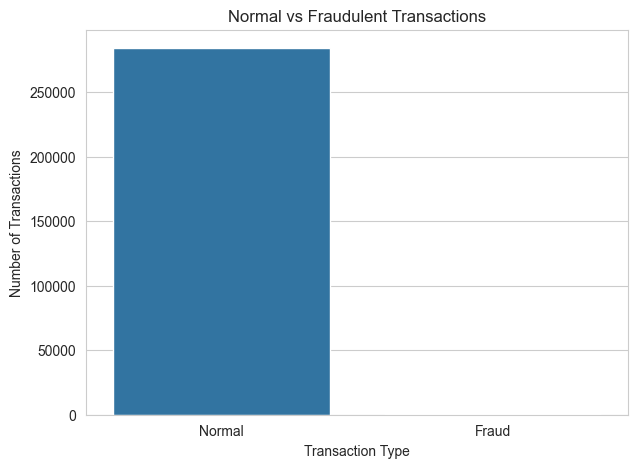

In [4]:
class_counts = df["Class"].value_counts()

plt.figure(figsize=(7, 5))
sns.barplot(
    x=["Normal", "Fraud"],
    y=[class_counts[0], class_counts[1]]
)

plt.title("Normal vs Fraudulent Transactions")
plt.xlabel("Transaction Type")
plt.ylabel("Number of Transactions")
plt.show()

**5. Analysing Transaction Amounts**

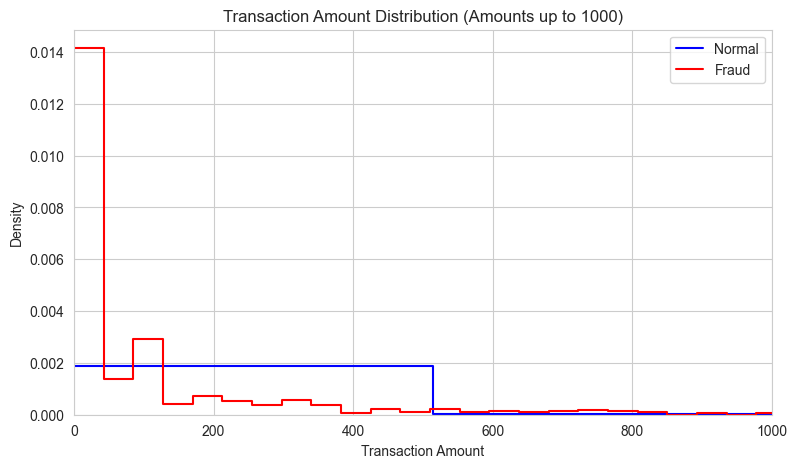

In [5]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df[df["Class"] == 0],
    x="Amount",
    bins=50,
    color="blue",
    label="Normal",
    stat="density",
    element="step",
    fill=False
)

sns.histplot(
    data=df[df["Class"] == 1],
    x="Amount",
    bins=50,
    color="red",
    label="Fraud",
    stat="density",
    element="step",
    fill=False
)

plt.xlim(0, 1000)
plt.title("Transaction Amount Distribution (Amounts up to 1000)")
plt.xlabel("Transaction Amount")
plt.ylabel("Density")
plt.legend()
plt.show()

**6. Analysing Transaction Time**

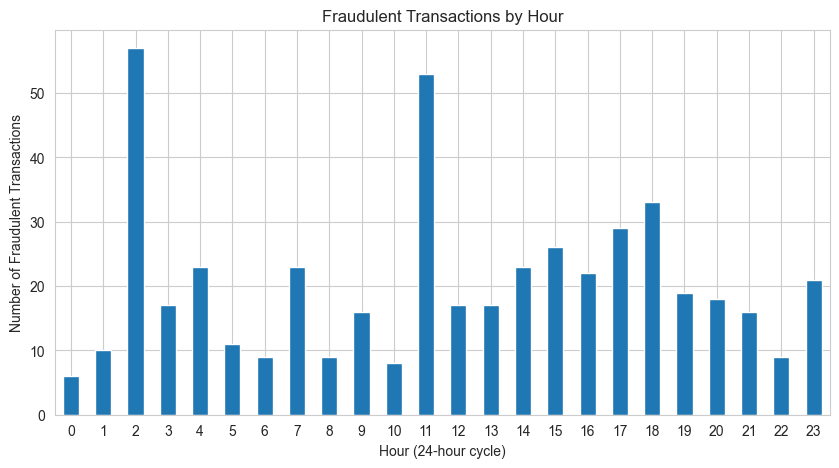

In [6]:
df["Hour"] = (df["Time"] / 3600) % 24

# Count transactions by hour and class
hourly_data = df.groupby(
    [df["Hour"].astype(int), "Class"]
).size().unstack(fill_value=0)

hourly_data.columns = ["Normal", "Fraud"]

# Plot hourly fraud counts
plt.figure(figsize=(10, 5))
hourly_data["Fraud"].plot(kind="bar")

plt.title("Fraudulent Transactions by Hour")
plt.xlabel("Hour (24-hour cycle)")
plt.ylabel("Number of Fraudulent Transactions")
plt.xticks(rotation=0)
plt.show()

**7. Handling Duplicate Rows**

In [7]:
# Inspect duplicate rows
duplicate_rows = df[df.duplicated(keep=False)]

print("Rows involved in duplicates:", len(duplicate_rows))

print("\nClass distribution among duplicate rows:")
print(duplicate_rows["Class"].value_counts())

print("\nDuplicate examples:")
display(duplicate_rows.head(10))

Rows involved in duplicates: 1854

Class distribution among duplicate rows:
Class
0    1822
1      32
Name: count, dtype: int64

Duplicate examples:


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V22,V23,V24,V25,V26,V27,V28,Amount,Class,Hour
32,26.0,-0.529912,0.873892,1.347247,0.145457,0.414209,0.100223,0.711206,0.176066,-0.286717,...,0.208105,-0.185548,0.001031,0.098816,-0.552904,-0.073288,0.023307,6.14,0,0.007222
33,26.0,-0.529912,0.873892,1.347247,0.145457,0.414209,0.100223,0.711206,0.176066,-0.286717,...,0.208105,-0.185548,0.001031,0.098816,-0.552904,-0.073288,0.023307,6.14,0,0.007222
34,26.0,-0.535388,0.865268,1.351076,0.147575,0.433680,0.086983,0.693039,0.179742,-0.285642,...,0.206537,-0.187108,0.000753,0.098117,-0.553471,-0.078306,0.025427,1.77,0,0.007222
35,26.0,-0.535388,0.865268,1.351076,0.147575,0.433680,0.086983,0.693039,0.179742,-0.285642,...,0.206537,-0.187108,0.000753,0.098117,-0.553471,-0.078306,0.025427,1.77,0,0.007222
112,74.0,1.038370,0.127486,0.184456,1.109950,0.441699,0.945283,-0.036715,0.350995,0.118950,...,0.605089,0.023092,-0.626463,0.479120,-0.166937,0.081247,0.001192,1.18,0,0.020556
113,74.0,1.038370,0.127486,0.184456,1.109950,0.441699,0.945283,-0.036715,0.350995,0.118950,...,0.605089,0.023092,-0.626463,0.479120,-0.166937,0.081247,0.001192,1.18,0,0.020556
114,74.0,1.038370,0.127486,0.184456,1.109950,0.441699,0.945283,-0.036715,0.350995,0.118950,...,0.605089,0.023092,-0.626463,0.479120,-0.166937,0.081247,0.001192,1.18,0,0.020556
115,74.0,1.038370,0.127486,0.184456,1.109950,0.441699,0.945283,-0.036715,0.350995,0.118950,...,0.605089,0.023092,-0.626463,0.479120,-0.166937,0.081247,0.001192,1.18,0,0.020556
220,145.0,-2.420413,1.947885,0.553646,0.983069,-0.281518,2.408958,-1.401613,-0.188299,0.675878,...,-1.238620,0.006927,-1.724222,0.239603,-0.313703,-0.188281,0.119831,6.00,0,0.040278
221,145.0,-2.420413,1.947885,0.553646,0.983069,-0.281518,2.408958,-1.401613,-0.188299,0.675878,...,-1.238620,0.006927,-1.724222,0.239603,-0.313703,-0.188281,0.119831,6.00,0,0.040278


**8.1. Checking duplicate counts by class**

In [8]:
duplicate_mask = df.duplicated(keep="first")

print("Duplicate rows by class:")
print(df.loc[duplicate_mask, "Class"].value_counts())

print("\nFraud cases in the original dataset:", (df["Class"] == 1).sum())
print("Normal cases in the original dataset:", (df["Class"] == 0).sum())

Duplicate rows by class:
Class
0    1062
1      19
Name: count, dtype: int64

Fraud cases in the original dataset: 492
Normal cases in the original dataset: 284315


**9. Creating a cleaned dataset**

In [9]:
df_clean = df.drop_duplicates().copy()

print("Original dataset shape:", df.shape)
print("Cleaned dataset shape:", df_clean.shape)

print("\nClass distribution after removing duplicates:")
print(df_clean["Class"].value_counts())

print("\nFraud percentage after cleaning:",
      round((df_clean["Class"].eq(1).mean()) * 100, 3), "%")

Original dataset shape: (284807, 32)
Cleaned dataset shape: (283726, 32)

Class distribution after removing duplicates:
Class
0    283253
1       473
Name: count, dtype: int64

Fraud percentage after cleaning: 0.167 %


# **Why Accuracy is misleading in Fraud Detection**

The credit card fraud dataset is highly imbalanced because fraudulent transactions represent only 0.167% of the cleaned dataset, while legitimate transactions account for approximately 99.833%.

Accuracy alone is misleading for this problem. A model that predicts every transaction as legitimate could achieve approximately 99.83% accuracy while failing to detect any fraudulent transactions.

Therefore, accuracy should not be used as the only evaluation metric. **Recall, Precision, F1-Score, and ROC-AUC** are also important.

- **Recall:** Measures how many actual fraudulent transactions the model detects.
- **Precision:** Measures how many transactions predicted as fraud are actually fraudulent.
- **F1-Score:** Balances precision and recall.
- **ROC-AUC:** Measures how well the model distinguishes fraudulent transactions from legitimate ones across different classification thresholds.

For fraud detection, recall is especially important because missing fraudulent transactions can cause financial losses. However, precision must also be considered to avoid flagging too many legitimate transactions.

**10. Train-Test Split with Stratification**

In [10]:
# Define features and target
X = df_clean.drop(columns=["Class", "Hour"])
y = df_clean["Class"]

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training set shape:", X_train.shape)
print("Testing set shape:", X_test.shape)

print("\nFraud cases in training set:", y_train.sum())
print("Fraud cases in testing set:", y_test.sum())

print("\nTraining fraud percentage:",
      round(y_train.mean() * 100, 3), "%")

print("Testing fraud percentage:",
      round(y_test.mean() * 100, 3), "%")

Training set shape: (226980, 30)
Testing set shape: (56746, 30)

Fraud cases in training set: 378
Fraud cases in testing set: 95

Training fraud percentage: 0.167 %
Testing fraud percentage: 0.167 %


**11. Scaling the Feature**

In [11]:
# Scale features without data leakage
scaler = StandardScaler()

X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

# Scale Amount and Time; PCA features V1–V28 are already transformed
X_train_scaled[["Amount", "Time"]] = scaler.fit_transform(
    X_train[["Amount", "Time"]]
)

X_test_scaled[["Amount", "Time"]] = scaler.transform(
    X_test[["Amount", "Time"]]
)

print("Training features shape:", X_train_scaled.shape)
print("Testing features shape:", X_test_scaled.shape)
print("\nFeature scaling completed!")

Training features shape: (226980, 30)
Testing features shape: (56746, 30)

Feature scaling completed!


**12. Model 1 — Logistic Regression**

In [12]:
# Train Logistic Regression with balanced class weights
lr_model = LogisticRegression(
    class_weight="balanced",
    max_iter=1000,
    random_state=42
)

lr_model.fit(X_train_scaled, y_train)

# Make predictions
lr_predictions = lr_model.predict(X_test_scaled)
lr_probabilities = lr_model.predict_proba(X_test_scaled)[:, 1]

print("Logistic Regression training completed!")

Logistic Regression training completed!


**13. Evaluate Model 1**

In [13]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

print("LOGISTIC REGRESSION RESULTS")
print("---------------------------")
print(f"Accuracy:  {accuracy_score(y_test, lr_predictions):.4f}")
print(f"Precision: {precision_score(y_test, lr_predictions, zero_division=0):.4f}")
print(f"Recall:    {recall_score(y_test, lr_predictions, zero_division=0):.4f}")
print(f"F1-Score:  {f1_score(y_test, lr_predictions, zero_division=0):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_test, lr_probabilities):.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test, lr_predictions,
    target_names=["Normal", "Fraud"],
    zero_division=0
))

print("Confusion Matrix:")
print(confusion_matrix(y_test, lr_predictions))

LOGISTIC REGRESSION RESULTS
---------------------------
Accuracy:  0.9752
Precision: 0.0562
Recall:    0.8737
F1-Score:  0.1057
ROC-AUC:   0.9658

Classification Report:
              precision    recall  f1-score   support

      Normal       1.00      0.98      0.99     56651
       Fraud       0.06      0.87      0.11        95

    accuracy                           0.98     56746
   macro avg       0.53      0.92      0.55     56746
weighted avg       1.00      0.98      0.99     56746

Confusion Matrix:
[[55258  1393]
 [   12    83]]


**14. Training RF**

In [ ]:
rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=12,
    min_samples_leaf=2,
    class_weight="balanced_subsample",
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

rf_predictions = rf_model.predict(X_test)
rf_probabilities = rf_model.predict_proba(X_test)[:, 1]

print("Random Forest training completed!")

**15. Evaluate RF**

In [16]:
print("RANDOM FOREST RESULTS")
print("---------------------")
print(f"Accuracy:  {accuracy_score(y_test, rf_predictions):.4f}")
print(f"Precision: {precision_score(y_test, rf_predictions, zero_division=0):.4f}")
print(f"Recall:    {recall_score(y_test, rf_predictions, zero_division=0):.4f}")
print(f"F1-Score:  {f1_score(y_test, rf_predictions, zero_division=0):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_test, rf_probabilities):.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    rf_predictions,
    target_names=["Normal", "Fraud"],
    zero_division=0
))

print("Confusion Matrix:")
print(confusion_matrix(y_test, rf_predictions))

RANDOM FOREST RESULTS
---------------------
Accuracy:  0.9994
Precision: 0.8861
Recall:    0.7368
F1-Score:  0.8046
ROC-AUC:   0.9708

Classification Report:
              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00     56651
       Fraud       0.89      0.74      0.80        95

    accuracy                           1.00     56746
   macro avg       0.94      0.87      0.90     56746
weighted avg       1.00      1.00      1.00     56746

Confusion Matrix:
[[56642     9]
 [   25    70]]


**16. Comparing Both Models**

In [17]:
comparison = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC"],
    "Logistic Regression": [
        accuracy_score(y_test, lr_predictions),
        precision_score(y_test, lr_predictions, zero_division=0),
        recall_score(y_test, lr_predictions, zero_division=0),
        f1_score(y_test, lr_predictions, zero_division=0),
        roc_auc_score(y_test, lr_probabilities)
    ],
    "Random Forest": [
        accuracy_score(y_test, rf_predictions),
        precision_score(y_test, rf_predictions, zero_division=0),
        recall_score(y_test, rf_predictions, zero_division=0),
        f1_score(y_test, rf_predictions, zero_division=0),
        roc_auc_score(y_test, rf_probabilities)
    ]
})

comparison.round(4)

,Metric,Logistic Regression,Random Forest
0,Accuracy,0.9752,0.9994
1,Precision,0.0562,0.8861
2,Recall,0.8737,0.7368
3,F1-Score,0.1057,0.8046
4,ROC-AUC,0.9658,0.9708


**17. Plot ROC Curves**

<Figure size 800x600 with 0 Axes>

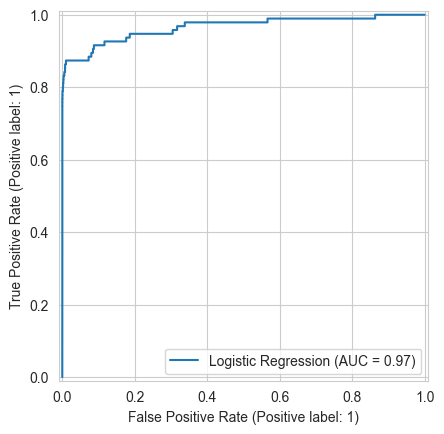

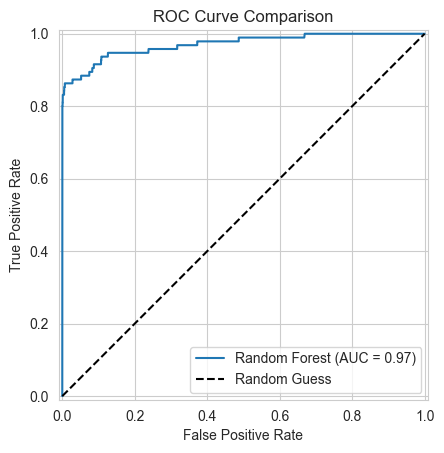

In [18]:
plt.figure(figsize=(8, 6))

RocCurveDisplay.from_predictions(
    y_test,
    lr_probabilities,
    name="Logistic Regression"
)

RocCurveDisplay.from_predictions(
    y_test,
    rf_probabilities,
    name="Random Forest"
)

plt.plot([0, 1], [0, 1], "k--", label="Random Guess")
plt.title("ROC Curve Comparison")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.show()

**18. Checking Both Models**

In [20]:
from sklearn.metrics import roc_curve, auc

lr_fpr, lr_tpr, _ = roc_curve(y_test, lr_probabilities)
rf_fpr, rf_tpr, _ = roc_curve(y_test, rf_probabilities)

print("Logistic Regression AUC:", round(auc(lr_fpr, lr_tpr), 4))
print("Random Forest AUC:", round(auc(rf_fpr, rf_tpr), 4))

Logistic Regression AUC: 0.9658
Random Forest AUC: 0.9708


In [21]:
print("Logistic Regression AUC:", auc(lr_fpr, lr_tpr))
print("Random Forest AUC:", auc(rf_fpr, rf_tpr))

print("Logistic Regression points:", len(lr_fpr))
print("Random Forest points:", len(rf_fpr))

Logistic Regression AUC: 0.9658392242808925
Random Forest AUC: 0.9708339797968912
Logistic Regression points: 56
Random Forest points: 7947


**19. Plots for both ROC Curves**

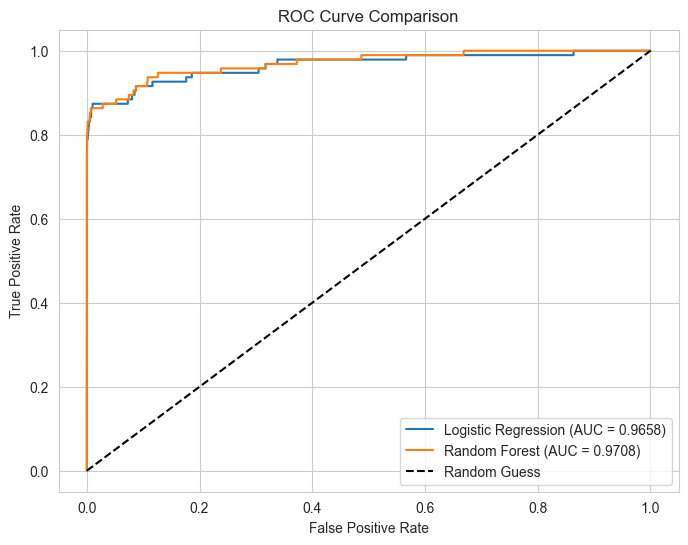

In [22]:
plt.figure(figsize=(8, 6))

plt.plot(lr_fpr, lr_tpr, label="Logistic Regression (AUC = 0.9658)")
plt.plot(rf_fpr, rf_tpr, label="Random Forest (AUC = 0.9708)")

plt.plot([0, 1], [0, 1], "k--", label="Random Guess")

plt.title("ROC Curve Comparison")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend(loc="lower right")
plt.grid(True)
plt.show()

**22. Future Importance**

Top 10 Important Features:


,Feature,Importance
14,V14,0.184599
10,V10,0.115803
12,V12,0.106951
4,V4,0.096772
17,V17,0.091450
3,V3,0.060852
16,V16,0.054804
11,V11,0.051335
2,V2,0.038172
9,V9,0.023930


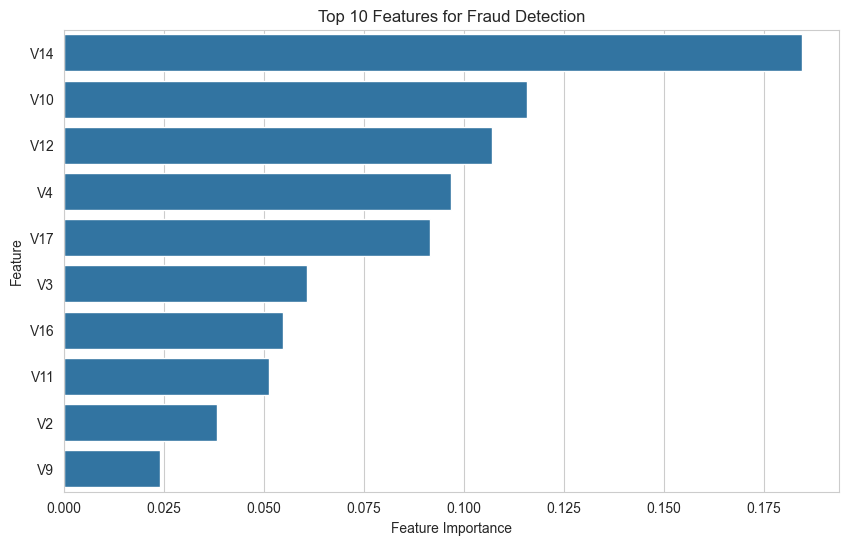

In [23]:
feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print("Top 10 Important Features:")
display(feature_importance.head(10))

plt.figure(figsize=(10, 6))
sns.barplot(
    data=feature_importance.head(10),
    x="Importance",
    y="Feature"
)

plt.title("Top 10 Features for Fraud Detection")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.show()

## Conclusion

In this project, two machine learning models for the detection of credit card fraud using the Credit Card Fraud Detection dataset have been built and evaluated.

There were only about 0.167% fraudulent transactions out of the cleaned dataset, meaning that the accuracy metric would not be enough for evaluation of the model.

The following two models were trained and tested against each other:

- **Logistic Regression** gave 87.37% of recall, detecting 83 cases out of 95 frauds in the test set but giving 1,393 false positive responses.
- **Random Forest** gave 88.61% precision and F1-score of 80.46% by detecting 70 frauds out of 95 and just 9 false positives.

The ROC-AUC of the second classifier turned out to be slightly better — 0.9708 vs 0.9658 of the Logistic Regression, and the classification was better balanced in terms of precision and recall.

The following features (V14, V10, V12, V4, and V17) have been chosen as most important by the Random Forest classifier.

Overall, Random Forest managed to provide fewer false alarms than Logistic Regression but detected fewer frauds.